# Introduction

In this project, we evaulate the asymptotic distribution of the correlation coefficient between two random fields. 

In [1]:
import numpy as np 
import gstools as gs
import pandas as pd
import matplotlib.pyplot as plt
import time

In [2]:
import importlib
import src
# allow reloading 
importlib.reload(src)

<module 'src' from 'c:\\Users\\jiyue\\OneDrive - UC San Diego\\python_projects\\corr\\src.py'>

In [6]:
x= (3,5)
tuple(slice(1,i + 3 )for i in x)

src.confidence_interval(0.3, 0.4)

(-0.5020199328649905, 0.8246059982510204)

In [30]:
print(src.gen_field(dim = 10, return_coordinate=False))
print(src.gen_field(dim = 10, return_coordinate=False, iid = True))
print(src.gen_field(dim = 10, return_coordinate=False, iid = False, method = 'gaussian_filter'))
print(src.gen_field(dim = (3,3), return_coordinate=False, iid = False, method = 'gstools'))
print(src.gen_field(dim = (3,3), return_coordinate=False, iid = False, method = 'gaussian_filter'))
print(src.gen_corr_field(rho = 0.5, dim = (3,3), return_coordinate=False, iid = False, method = 'gaussian_filter'))

[ 0.12000291 -1.38436817 -2.45951459 -2.04541852 -1.13030302  1.27186611
  1.87910888 -0.24190306 -0.61205778  0.24474767]
[-0.19622643  0.24356956  1.11430046 -1.34049669 -2.28870444 -0.73964746
 -0.02529965  1.31510368 -0.72399988 -0.02119109]
[ 1.47910868  1.04931428 -0.35323205 -0.86956905  0.11189279  1.27241898
  1.03317456 -0.08280718 -0.52774162  0.35010423]
[[2.3111191  0.03908228 0.18002201]
 [0.76963995 0.90291155 0.05562714]
 [0.35108433 0.87509514 0.53257498]]
[[-0.06290506  0.92339163  1.30089634]
 [ 0.4247467   1.4638126   1.24383805]
 [-0.22782538  0.30835238 -0.05854691]]
(array([[ 0.59812658,  0.84429711,  0.64323375],
       [-0.87563638, -0.24765637,  0.15304042],
       [-0.49472644, -0.26719194,  0.29810906]]), array([[ 0.21720348,  1.04270268,  1.41579393],
       [-0.80358905, -0.52107474,  0.32567224],
       [-1.35068323, -1.35022311, -0.66028895]]))


In [5]:
nx = 20
ny = 30
nz = 10
dim = (nx, ny)
dim = (15,)
dim = (nx, ny, nz)
X =  np.random.normal(size = dim)
Y = np.random.normal(size = dim)
exp = src.est_exp_X0Yh(X, Y, return_counts_lags = False)
print(exp.shape)
lags_x = np.arange(-(nx-1), nx)
lags_y = np.arange(-(ny-1), ny)
lags_x_all, lags_y_all = np.meshgrid(lags_x, lags_y)
weights =(1-np.abs(lags_x_all)/10)*(1-np.abs(lags_y_all)/10)
print('weights', weights)
lag_ls = [np.arange(-(dim_i-1), dim_i) for dim_i in dim]
lags_all_ls = np.meshgrid(*lag_ls)
weights_ls = [1-np.abs(i)/10 for i in lag_ls]
print(weights_ls)
from functools import reduce
weights1 = reduce(np.multiply, np.ix_(*weights_ls))
print('weights1', weights1)



(39, 59, 19)
weights [[1.71 1.52 1.33 ... 1.33 1.52 1.71]
 [1.62 1.44 1.26 ... 1.26 1.44 1.62]
 [1.53 1.36 1.19 ... 1.19 1.36 1.53]
 ...
 [1.53 1.36 1.19 ... 1.19 1.36 1.53]
 [1.62 1.44 1.26 ... 1.26 1.44 1.62]
 [1.71 1.52 1.33 ... 1.33 1.52 1.71]]
[array([-0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,
        0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  0.9,  0.8,
        0.7,  0.6,  0.5,  0.4,  0.3,  0.2,  0.1,  0. , -0.1, -0.2, -0.3,
       -0.4, -0.5, -0.6, -0.7, -0.8, -0.9]), array([-1.9, -1.8, -1.7, -1.6, -1.5, -1.4, -1.3, -1.2, -1.1, -1. , -0.9,
       -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,
        0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  0.9,  0.8,  0.7,
        0.6,  0.5,  0.4,  0.3,  0.2,  0.1,  0. , -0.1, -0.2, -0.3, -0.4,
       -0.5, -0.6, -0.7, -0.8, -0.9, -1. , -1.1, -1.2, -1.3, -1.4, -1.5,
       -1.6, -1.7, -1.8, -1.9]), array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.9, 0.8, 0.7,
       0.6, 0.5,

In [7]:
#print(src.corr_old(X, Y, M='linear', true_rho = None, method = 'qs', check = False,     b_qs = 5))
print(X)
print('X.shape:', X.shape)
print(src.corr(X, Y, M='linear', true_rho = None, method = 'bartlett', check = False, 
         b_qs = 5))

[[[ 0.99185285  1.28417836  0.60341482 ... -1.53709675 -1.14443981
    0.84130556]
  [ 0.08571713  0.04641682  0.50339473 ... -0.04251291 -0.25686965
    0.68041177]
  [ 1.50983117  0.16925899  0.11101321 ...  1.45151139 -1.32973723
   -0.88233195]
  ...
  [ 1.37799505 -1.6623076   0.76729744 ... -1.01648742 -0.19070218
   -0.0331237 ]
  [ 0.7796769   1.27715456  0.20486286 ... -1.77306349 -0.22990878
   -0.84169663]
  [ 0.07664719  1.5114724  -0.47277263 ...  0.49674764  0.28648388
    0.06043129]]

 [[ 0.1780085  -0.37008442 -1.1189272  ... -0.47029499 -0.84828107
   -0.35464554]
  [ 0.57095295 -0.78701017  0.78740874 ... -0.44867884 -0.50265038
   -0.14812814]
  [-0.90299127 -0.79158472 -1.42221628 ...  1.10478406 -1.94940949
   -0.07692652]
  ...
  [ 0.40768764 -1.18761547  1.07426501 ... -0.95405691  0.26358574
   -0.2877169 ]
  [ 0.33589858  0.58041218 -1.40599242 ... -1.10948914 -0.11480296
   -0.41868041]
  [ 0.62702278  1.63729559  0.59821879 ...  0.95013563  0.54629394
    1.

(-0.011700899689751585, 0.011584807766343956, 0.6392381191253662, array([4., 6., 2.]))


# Simulations

First we simulate two isotropic Gaussian random fields and look at their semi-variograms. Note the semi-variogram is defined as $\gamma(s_1, s_2)  = \frac{1}{2}\text{Var}(Z(s_1)-Z(s_2))$. 

In [339]:
dim = np.array((10,4))
np.ceil(dim**0.3)
#[np.arange(-(dim_i-1), dim_i) for dim_i in dim]


array([2., 2.])

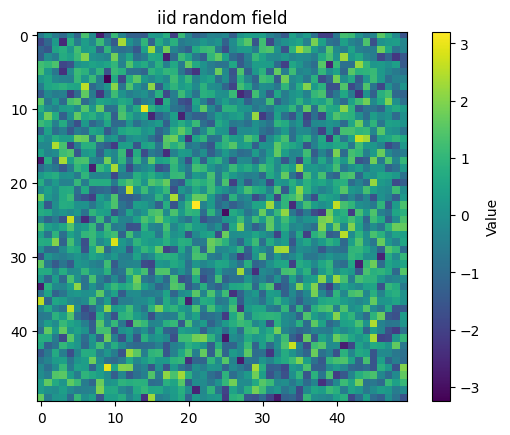

In [ ]:
nx = ny = 50
U0 = np.random.normal(loc=0, scale=1, size=(nx, ny))
plt.imshow(U0)
plt.colorbar(label="Value")
plt.title('iid random field')
plt.show()

shape of the random field: (50, 50)


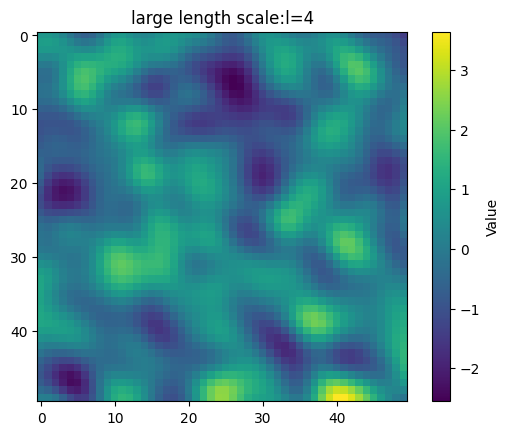

bin_center: [ 0.48122545  1.44367634  2.40612724  3.36857814  4.33102903  5.29347993
  6.25593083  7.21838172  8.18083262  9.14328352 10.10573441 11.06818531
 12.03063621 12.9930871  13.955538   14.9179889  15.88043979 16.84289069
 17.80534159 18.76779248 19.73024338 20.69269428 21.65514517 22.61759607]
gamma: [0.         0.06885795 0.22583396 0.39498419 0.54626051 0.66560875
 0.7438796  0.77988224 0.79601829 0.79746563 0.80069871 0.81489395
 0.82588239 0.85223058 0.87448577 0.89050588 0.90586144 0.90893654
 0.90689264 0.89936219 0.88905031 0.87096318 0.84365073 0.81192602]
The number of point pairs found for each bin: [    0  9702 18816 22936 26866 34840 46484 41214 55836 50572 53054 65944
 60692 75746 73384 68152 75242 78812 73592 90202 71032 81964 91286 83060]
gamma_truth: [0.01130107 0.09723111 0.24733517 0.42702038 0.60171931 0.74721468
 0.8535036  0.92247985 0.96254457 0.98347553 0.9933434  0.99755156
 0.99917768 0.99974782 0.99992939 0.99998195 0.99999579 0.9999991
 0.99999983 0

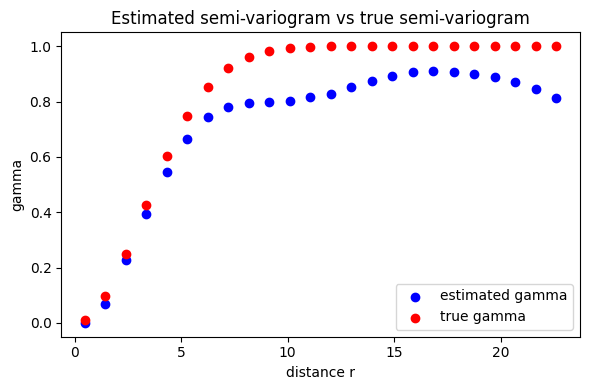

In [85]:
# explore gstools
#----- 1.specify the covariance function
# a larger length scale gives a smoother field
scale = 4
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
#----- 2.generate the random field class based on the covariance function 
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)
#----- 3. create realizations of the random field
# structured grid
nx = ny = 50
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2

#print('X coordinates:', x, '\nY coordinates:', y)
# the random field depends on the corrodinates
U = srf.structured([x, y], seed = 1)
print('shape of the random field:', U.shape)
plt.imshow(U)
plt.colorbar(label="Value")
plt.title(f"large length scale:l={scale}")
plt.show()



#----- 4. estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
# mesh_type (str, optional) – ‘structured’ / ‘unstructured’, indicates whether the pos tuple describes the axis or the point coordinates. Default: ‘unstructured’
# same: bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y), mesh_type = 'structured'), return_counts = True, mesh_type = 'structured')
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = U, return_counts = True, mesh_type = 'structured')
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)
print('gamma_truth:', gamma_truth)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()

# note under an isotropic field with variance 1, when the distance increases, covariance decreaes and  gamma increases and is close to 1. 

bin_center: [ 2.1949773  6.5849319 10.9748865 15.3648411 19.7547957 24.1447503
 28.5347049 32.9246595 37.3146141 41.7045687 46.0945233 50.4844779
 54.8744325 59.2643871 63.6543417 68.0442963]
gamma: [0.06669588 0.30805653 0.56094394 0.6877291  0.71000878 0.70988862
 0.74155047 0.80162061 0.85128581 0.86167247 0.82988191 0.75309732
 0.63395591 0.52847342 0.50241158 0.57782494]
The number of point pairs found for each bin: [444 435 426 417 408 399 390 381 372 482 351 342 333 324 315 306]
gamma_truth: [0.03712604 0.28858179 0.61163862 0.84336001 0.95332065 0.98972215
 0.998328   0.99979903 0.99998215 0.99999883 0.99999994 1.
 1.         1.         1.         1.        ]


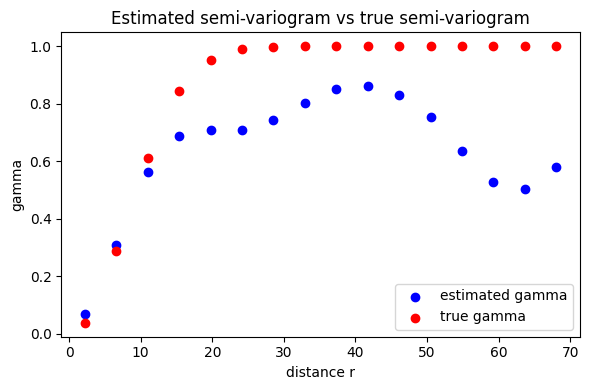

In [ ]:
#----- 4. estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
# mesh_type (str, optional) – ‘structured’ / ‘unstructured’, indicates whether the pos tuple describes the axis or the point coordinates. Default: ‘unstructured’
# this is for a realization of field on nx=ny points, instead of nx*ny previously 
# note the number of valid pairs is much smaller
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)
print('gamma_truth:', gamma_truth)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()


2
RandMeth(model=Gaussian(dim=2, var=1.0, len_scale=10.0), mode_no=1000, seed=None)
Gaussian(dim=2, var=1.0, len_scale=10.0)
SRF
unstructured
[2.11602263 1.95295843 1.68156527 1.35843484 1.0417219 ]
[2.11602263 1.95295843 1.68156527 1.35843484 1.0417219 ]
[[2.11602263 2.02728131 1.90160454 1.74839817 1.57847406]
 [2.06936353 1.95295843 1.80748338 1.64388402 1.47379625]
 [1.98297139 1.84253457 1.68156527 1.51206453 1.34600156]
 [1.86095678 1.70119389 1.52951346 1.35843484 1.19976876]
 [1.70986741 1.53639844 1.35911542 1.19049481 1.0417219 ]]
[[2.11602263 2.02728131 1.90160454 1.74839817 1.57847406]
 [2.06936353 1.95295843 1.80748338 1.64388402 1.47379625]
 [1.98297139 1.84253457 1.68156527 1.51206453 1.34600156]
 [1.86095678 1.70119389 1.52951346 1.35843484 1.19976876]
 [1.70986741 1.53639844 1.35911542 1.19049481 1.0417219 ]]
RandMeth(model=Gaussian(dim=2, var=1.0, len_scale=10.0), mode_no=1000, seed=None)


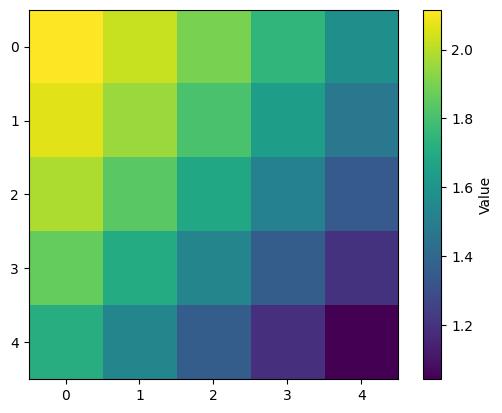

In [124]:
# a larger length scale gives a smoother field
scale = 10
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
# create the srf object based on the covariance function 
srf = gs.SRF(model)
# some attributes of the srf class
print(srf.dim)
## generator has seed =None
print(srf.generator)
print(srf.model)
print(srf.name)
print(srf.mesh_type)


# structured grid
nx = ny = 5
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2

# some methods of the srf class
## by default, srf keeps the seed from the generator so the array generated is not random, and it generates a field on an unstructured mesh
U1 = srf((x,y), mesh_type='unstructured')
print(U1)
U1_rerun = srf((x,y), mesh_type='unstructured')
print(U1_rerun)
U2 = srf((x,y), mesh_type='structured')
print(U2)
U3 = srf.structured((x,y))
print(U3)
#print(srf((x,y), seed=1))
#print(srf((x,y), seed=2))
## the generator has seed=2 now
print(srf.generator)
plt.imshow(U2)
plt.colorbar(label="Value")
plt.show()

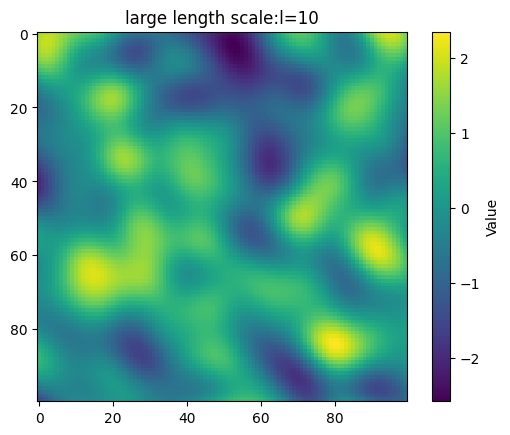

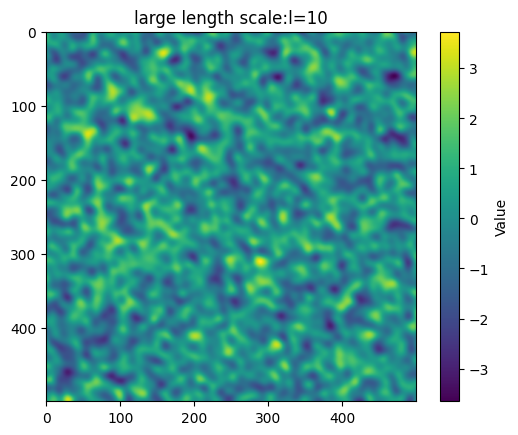

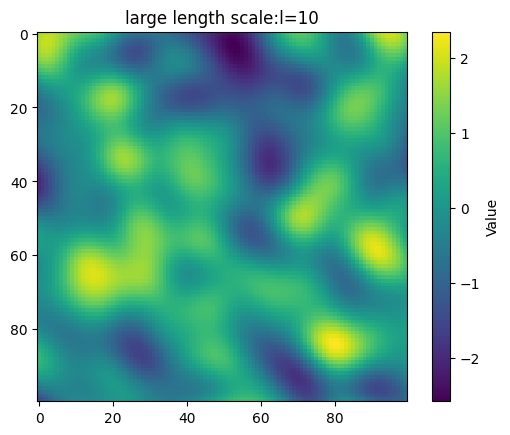

In [141]:
# a larger length scale gives a smoother field
scale = 10
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)

# structured grid
nx = ny = 100
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2

# the random field depends on the corrodinates
U1 = srf.structured([x, y], seed = 1)
plt.imshow(U1)
plt.colorbar(label="Value")
plt.title(f"large length scale:l={scale}")
plt.show()



# structured grid
nx = ny = 500
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2

# the random field depends on the corrodinates
U2 = srf.structured([x, y], seed = 1)
plt.imshow(U2)
plt.colorbar(label="Value")
plt.title(f"large length scale:l={scale}")
plt.show()

# Compute the start and end indices
center_size = 100
start = (nx - center_size) // 2   
end = start + center_size      
# note the cropped version is the same as the smaller version   
U_crop = U2[start:end, start:end]

# the random field depends on the corrodinates
plt.imshow(U_crop)
plt.colorbar(label="Value")
plt.title(f"large length scale:l={scale}")
plt.show()


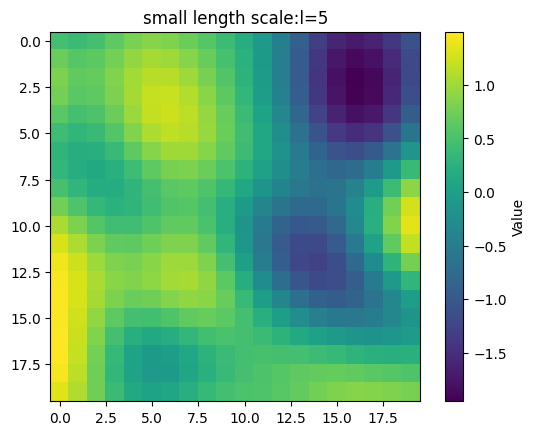

bin_center: [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5]
gamma: [0.         0.03151538 0.11642166 0.         0.23254027 0.35733882
 0.         0.4774146  0.58987557 0.69783662 0.         0.80561103
 0.91550099 0.         1.02520431 1.12664919 1.20781342 0.
 1.25579906]
The number of point pairs found for each bin: [  0 380 360   0 340 320   0 300 280 260   0 240 220   0 200 180 160   0
 140]


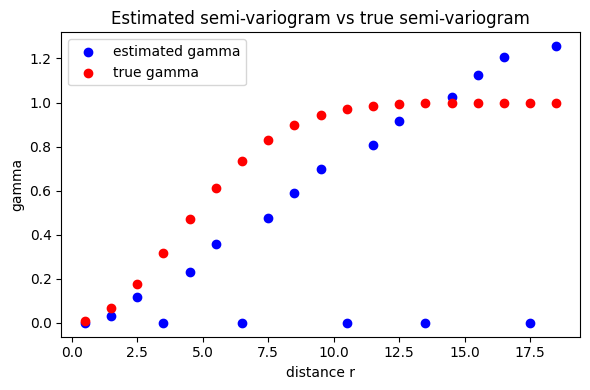

bin_center: [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5]
gamma: [0.         0.03719036 0.12474836 0.22337399 0.31802933 0.41068371
 0.4738421  0.51553651 0.54897056 0.58357852 0.62406775 0.68162106
 0.74775275 0.80731655 0.88259386 0.91977948 0.93804776 0.94901873
 0.9176295 ]
The number of point pairs found for each bin: [   0 1482 2736 3196 3586 5440 4544 5514 5844 5306 5772 4900 5374 5344
 4376 4026 3308 3156 2346]


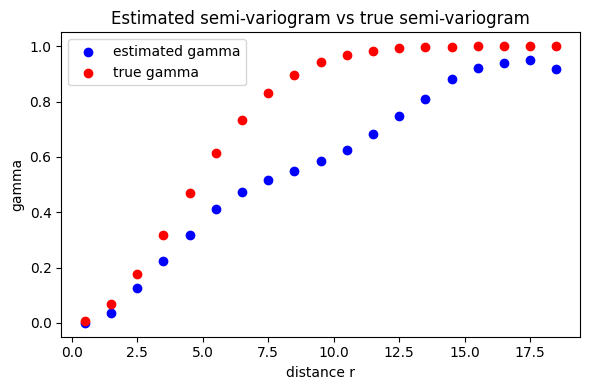

bin_center: [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5]
gamma: [0.         0.03550133 0.14007982 0.         0.29749642 0.47585477
 0.         0.63516614 0.74272503 0.79190166 0.         0.80355738
 0.80282166 0.         0.79580822 0.76741593 0.69192538 0.
 0.5531742 ]
The number of point pairs found for each bin: [ 0 19 18  0 17 16  0 15 14 13  0 12 11  0 10  9  8  0  7]


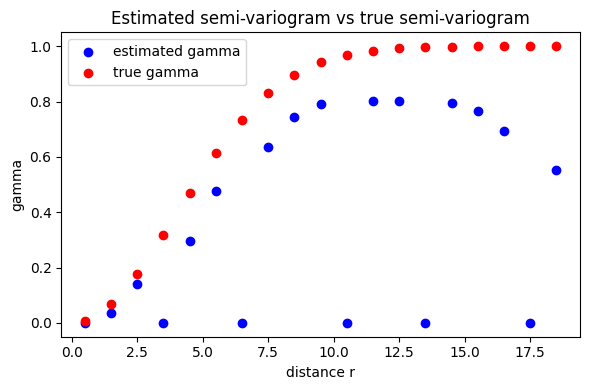

In [ ]:
# a smaller length scale gives a rougher field
scale = 5
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)

# structured grid
nx = ny = 20
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2
U = srf.structured([x, y],seed = 1)
plt.imshow(U)
plt.colorbar(label="Value")
plt.title(f"small length scale:l={scale}")
plt.show()

# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
# not sure the behavior of this, seems wrong.
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = U, return_counts = True, mesh_type = 'unstructured', bin_edges = range(20))
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()

# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = U, return_counts = True, mesh_type = 'structured', bin_edges = range(20))
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()

# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True, mesh_type = 'unstructured', bin_edges = range(20))
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
X, Y, x, y = src.gen_field(rho=0.4, nx = 20, seed = 1, len_scale = 1, return_coordinate = True)
print(X.shape, Y.shape)
print(x,y)
print('mean of X:', X.mean())
print('SD of X', X.std())
#src.corr(X, Y, M=None,  method = 'iid', check = False, true_rho = None)
src.corr(X, Y, M=None,  method = 'bartlett', check = False)
src.corr(X, Y, M=None,  method = 'qs', check = True)

(20, 20) (20, 20)
[-10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7
   8   9] [-10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7
   8   9]
mean of X: 0.0033926358848218683
SD of X 0.9266805348298287
[[ 0.60556845 -0.70212359  0.08040567]
 [-0.70212359 -2.55492601 -2.08632711]
 [ 0.08040567 -2.08632711  3.7061572 ]]
[[ 0.09769253 -2.20126983 -0.56682471]
 [-2.20126983 -6.81699033 -4.27491328]
 [-0.56682471 -4.27491328  4.96365163]]


(0.3984587096803254, 0.8875460455383819, 0.009906530380249023)

In [163]:
print(X.ravel().shape)
np.corrcoef(X.ravel(), Y.ravel())
nx = 10
ny = 10
x = np.arange(nx) - nx//2
y = np.arange(ny) - ny//2
xx, yy = np.meshgrid(x, y, indexing="ij")
print(xx)
print(yy)

(4096,)
[[-5 -5 -5 -5 -5 -5 -5 -5 -5 -5]
 [-4 -4 -4 -4 -4 -4 -4 -4 -4 -4]
 [-3 -3 -3 -3 -3 -3 -3 -3 -3 -3]
 [-2 -2 -2 -2 -2 -2 -2 -2 -2 -2]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 1  1  1  1  1  1  1  1  1  1]
 [ 2  2  2  2  2  2  2  2  2  2]
 [ 3  3  3  3  3  3  3  3  3  3]
 [ 4  4  4  4  4  4  4  4  4  4]]
[[-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]]


In [ ]:
# back up
nx, ny = X.shape
x = np.arange(nx) - nx//2
y = np.arange(ny) - ny//2
xx, yy = np.meshgrid(x, y, indexing="ij")
l2_square = xx**2 + yy**2   # L2 norm squared gird
# Count how many cells fall in each unique radius 
unique_l2_square, counts = np.unique(l2_square, return_counts=True)
unique_l2 = np.sqrt(unique_l2_square)
    

In [296]:
dim = (2,3)
lag_ls = [np.arange(-(dim_i-1), dim_i) for dim_i in dim]
#lag_ls
grids = np.ix_(*lag_ls)
for i in grids: 
    print(i) 

[[-1]
 [ 0]
 [ 1]]
[[-2 -1  0  1  2]]


In [307]:
np.meshgrid(*[[1,2,3], [5,6], [10]])
isinstance((3,4), int)


False

In [16]:
# the two are different 
from scipy.signal import correlate2d
print('corr (X,Y):', correlate2d(X, Y))
print('corr (Y,X):', correlate2d(Y, X))

corr (X,Y): [[2.40196867 5.58359229 2.43240144]
 [3.22056533 7.00399361 1.36404615]
 [0.33041044 1.72794221 0.18556846]]
corr (Y,X): [[0.18556846 1.72794221 0.33041044]
 [1.36404615 7.00399361 3.22056533]
 [2.43240144 5.58359229 2.40196867]]


In [ ]:
import tracemalloc
#X = np.array([1,2,3,4]).reshape((2,2))
#Y = np.array([0,1,1,0]).reshape((2,2))
nx = 100
X = np.random.normal(size = (nx,nx))
Y = np.random.normal(size = (nx,nx))
start = time.time()
tracemalloc.start()
res = src.est_exp_X0Yh(X, Y, True)
# Get current and peak memory usage
current, peak = tracemalloc.get_traced_memory()
print(f"Peak memory usage: {peak / 10**6:.2f} MB")
tracemalloc.stop()
end = time.time()
print(f"Runtime: {end - start:.4f} seconds")
print(res)

Peak memory usage: 1.69 MB
Runtime: 0.0100 seconds
(array([[-0.43777545,  2.19630004, -2.90762063, ...,  0.20297348,
         1.53358557, -2.66767189],
       [ 0.89982174,  0.80860608, -4.30669839, ..., -0.34704069,
         0.91453078, -1.53487622],
       [ 0.67062096, -3.15248515, 14.48571701, ..., -3.08842796,
         1.40434004,  0.3139089 ],
       ...,
       [ 0.91096312, -2.14756443,  1.76711984, ..., -1.85445823,
         0.20453166, -0.57603397],
       [-1.06062229,  2.34461552, -0.48467301, ...,  0.94210934,
        -0.37054791,  0.51418433],
       [-0.70689008,  2.14822195, -0.86338007, ..., -0.56497947,
         0.58940457, -0.08457388]]), array([[1., 2., 3., ..., 3., 2., 1.],
       [2., 4., 6., ..., 6., 4., 2.],
       [3., 6., 9., ..., 9., 6., 3.],
       ...,
       [3., 6., 9., ..., 9., 6., 3.],
       [2., 4., 6., ..., 6., 4., 2.],
       [1., 2., 3., ..., 3., 2., 1.]]), array([[-0.43777545,  1.09815002, -0.96920688, ...,  0.06765783,
         0.76679279, -2.667

In [13]:
x1,y1 = np.meshgrid((-1,0,1), (-2,-1,0,1,2))
print(x1)
print(y1)


[[-1  0  1]
 [-1  0  1]
 [-1  0  1]
 [-1  0  1]
 [-1  0  1]]
[[-2 -2 -2]
 [-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]]


In [40]:
nx =3
ny =3
M = (2,2)
lags_x = np.arange(-(nx-1), nx)
lags_y = np.arange(-(ny-1), ny)
lags_x_all, lags_y_all = np.meshgrid(lags_x, lags_y)
(np.abs(lags_x_all)<M[0])*(np.abs(lags_y_all)<M[1])*(1-np.abs(lags_x_all)/M[0])*(1-np.abs(lags_y_all)/M[1])

array([[1., 1., 1.],
       [1., 1., 1.]])

In [19]:
print(src.corr(X,Y, M = (2,2), true_rho = 0, method = 'naive'))
print(src.corr(X,Y, M = (2,2), true_rho = 0, method = 'bartlett'))
print(src.corr(X,Y, M = (2,2), true_rho = None, method = 'bartlett'))
print(src.corr(X,Y, M = (2,2), true_rho = None, method = 'qs'))

NameError: name 'X' is not defined

In [134]:
rng = np.random.default_rng(1)
rng.integers(0,19)

8

## Example usage 

In [28]:
nx =100
X, Y  =  src.gen_corr_field(0.9,
    dim=(nx, nx),
    var=1.0,
    seed=None,
    M_trunc=None,
    return_coordinate=False,
    method="gaussian_filter",
    fwhm=4)

print("------------SE estimation: different constants:")
for m_method in ['auto', 'cubic_root']:
    for constant in [0.5, 1, 1.5, 2]:
            print('M method:', m_method, 'constant:', constant, 
                  src.corr(X, Y, M=m_method, true_rho=None, se_method="general", check=False, constant = constant))
            
print("------------SE estimation: general vs gauss vs indep (naive use of clifford) vs iid method:")
for m_method in ['auto', 'cubic_root']:
        for se_method in ["general", "gauss", "indep", "iid"]:
            print('M method:', m_method, 'se method:', se_method,
                  src.corr(X, Y, M=m_method, true_rho=None, se_method=se_method, check=False, constant =1))


------------SE estimation: different constants:
M method: auto constant: 0.5 (0.8984248228038397, 0.004588011574399716, 0.06739849818665751, 0.24187088012695312, array([5., 5.]))
M method: auto constant: 1 (0.8984248228038397, 0.005272719476014444, 0.10944487325254935, 0.21588397026062012, array([10., 10.]))
M method: auto constant: 1.5 (0.8984248228038397, 0.005764641563746108, 0.15306206728384458, 0.23906803131103516, array([15., 15.]))
M method: auto constant: 2 (0.8984248228038397, 0.006140638668010171, 0.19726592752298958, 0.2321927547454834, array([20., 20.]))
M method: cubic_root constant: 0.5 (0.8984248228038397, 0.003772769420268658, 0.0408897819606636, 0.2706155776977539, array([2., 2.]))
M method: cubic_root constant: 1 (0.8984248228038397, 0.004412554909242022, 0.059108529641854986, 0.36365604400634766, array([4., 4.]))
M method: cubic_root constant: 1.5 (0.8984248228038397, 0.004738268605441203, 0.07564193590183149, 0.30008888244628906, array([6., 6.]))
M method: cubic_roo

## Simultion runs 

In [3]:
# create various simulation settings
from itertools import product
#nx_ls = [100,200,500,800,1000]
#nx_ls = [50, 100,150, 200, 300, 400, 500]
#nx_ls = [600, 700, 800, 900, 1000]
#nx_ls = [50, 100,200, 300, 400, 500, 800, 1000, 1200, 1500,2000, 2500, 3000]
#nx_ls = [100]
## final version fo 2d
#nx_ls = [10,20,30,50,80, 100, 150, 200, 300, 400, 500]
nx_ls = [25, 50, 75, 100, 125, 150, 175, 200, 225, 250]
#nx_ls = [100, 150, 200, 300, 400, 500]

rho_ls = [0, 0.4, -0.9]
#rho_ls = [-0.4]
#rho_ls = [0, 0.4, -0.9, 0.9]
#len_scale_ls = [0.1, 1, 3, 5]
#len_scale_ls = [1]
len_scale_ls = [None]
fwhm_ls = [1,2,3,4]
#fwhm_ls = [2,3,4]
#fwhm_ls = [1]
gen_method_ls = ['gaussian_filter']
#gen_method_ls = ['gstools']
#n_dim_ls = [1]#
n_dim_ls = [2]
#n_dim_ls = [3]
#distribution_ls = ['gaussian', 'chisq']
distribution_ls = ['gaussian']
#noise_df_ls = [3]
noise_df_ls = [1]
trans_ls = [None, 'square']
# (mask, mask_axes): no mask, or a fixed ellipse with semi-axes (1, 0.8) as fractions of half the side lengths
#mask_ls = [(None, None), ('ellipse', (1, 0.8))]
mask_ls = [('ellipse', (1, 0.8))]
# smoothing ratio: the field entering only Y has fwhm / fwhm_ratio, so with 2 Y is partly rougher than X
# (1 = same smoothness for X and Y; use [1, 2] to run both)
fwhm_ratio_ls = [2]
setting_df = pd.DataFrame(product(nx_ls, n_dim_ls, rho_ls, len_scale_ls,  fwhm_ls, gen_method_ls, distribution_ls, noise_df_ls, trans_ls, mask_ls, fwhm_ratio_ls), 
                          columns=['nx', 'n_dim', 'rho', 'len_scale',  'fwhm', 'gen_method', 'distribution','noise_df', 'trans', 'mask_spec', 'fwhm_ratio'])
setting_df[['mask', 'mask_axes']] = pd.DataFrame(setting_df.pop('mask_spec').tolist(), index=setting_df.index)
print(setting_df)

      nx  n_dim  rho len_scale  fwhm       gen_method distribution  noise_df  \
0     25      2  0.0      None     1  gaussian_filter     gaussian         1   
1     25      2  0.0      None     1  gaussian_filter     gaussian         1   
2     25      2  0.0      None     2  gaussian_filter     gaussian         1   
3     25      2  0.0      None     2  gaussian_filter     gaussian         1   
4     25      2  0.0      None     3  gaussian_filter     gaussian         1   
..   ...    ...  ...       ...   ...              ...          ...       ...   
235  250      2 -0.9      None     2  gaussian_filter     gaussian         1   
236  250      2 -0.9      None     3  gaussian_filter     gaussian         1   
237  250      2 -0.9      None     3  gaussian_filter     gaussian         1   
238  250      2 -0.9      None     4  gaussian_filter     gaussian         1   
239  250      2 -0.9      None     4  gaussian_filter     gaussian         1   

      trans  fwhm_ratio     mask mask_a

In [4]:
from itertools import product
# negative estimate for newey-west may occur in practive when M is extremely too large 
#M_ls = [(3,3),(4,4), (6,6), (8,8), (10,10), (30,30), (40,40), (50,50), (60,60), (70,70)]
#M_ls = [(10,10), (30,30)]
#M_ls = ['cubic_root', 'linear']
#M_ls = ['cubic_root']
#M_ls = ['auto', 'cubic_root', 'linear']
M_ls = ['auto', 'plugin']
#b_qs_ls =[3,5,6,8]
b_qs_ls = [None]
#constant_ls = [0.3, 0.5, 0.8, 1, 1.5, 2, 2.5, 3]
constant_ls = [1]

method_ls = ['iid', 'indep', 'general', 'gauss']
#method_ls = ['gauss']
kernel_ls = ['bartlett']
#use_true_rho_ls = [True, False]
use_true_rho_ls = [False]
method_df = pd.DataFrame(product(use_true_rho_ls, method_ls, kernel_ls, M_ls, b_qs_ls, constant_ls), 
                          columns=['use_true_rho', 'method', 'kernel', 'M', 'b_qs', 'constant'])
print(method_df)

   use_true_rho   method    kernel       M  b_qs  constant
0         False      iid  bartlett    auto  None         1
1         False      iid  bartlett  plugin  None         1
2         False    indep  bartlett    auto  None         1
3         False    indep  bartlett  plugin  None         1
4         False  general  bartlett    auto  None         1
5         False  general  bartlett  plugin  None         1
6         False    gauss  bartlett    auto  None         1
7         False    gauss  bartlett  plugin  None         1


In [5]:
src.sim_multiple(setting_df.head(), method_df, m_sim=5, return_summary = True)

----performing simulation, current setting number: 1, remaining settings: 4----
----performing simulation, current setting number: 2, remaining settings: 3----
----performing simulation, current setting number: 3, remaining settings: 2----
----performing simulation, current setting number: 4, remaining settings: 1----
----performing simulation, current setting number: 5, remaining settings: 0----


,setting_id,method_id,M0,bias_mean,est_sd,se_mean,n_se_na,cover_rate,cover_rate_raw,power,...,trans,mask,mask_axes,n_obs,use_true_rho,method,kernel,M,b_qs,constant
0,0,0,NaN,0.009696,0.031404,0.050657,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,iid,bartlett,auto,None,1
1,0,1,NaN,0.009696,0.031404,0.050657,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,iid,bartlett,plugin,None,1
2,0,2,5.0,0.009696,0.031404,0.050509,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,indep,bartlett,auto,None,1
3,0,3,1.0,0.009696,0.031404,0.050597,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,indep,bartlett,plugin,None,1
4,0,4,5.0,0.009696,0.031404,0.045043,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,general,bartlett,auto,None,1
5,0,5,1.0,0.009696,0.031404,0.050127,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,general,bartlett,plugin,None,1
6,0,6,5.0,0.009696,0.031404,0.050699,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,gauss,bartlett,auto,None,1
7,0,7,1.0,0.009696,0.031404,0.050625,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,gauss,bartlett,plugin,None,1
8,0,5,2.0,0.009696,0.031404,0.050127,0,1.0,1.0,0.0,...,NaN,ellipse,"(1, 0.8)",389,False,general,bartlett,plugin,None,1
9,1,0,NaN,-0.014481,0.075797,0.050458,0,0.8,0.8,0.2,...,square,ellipse,"(1, 0.8)",389,False,iid,bartlett,auto,None,1


In [6]:
import joblib
#out_mean_1 = src.sim_multiple_mean(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out_mean_1, 'results/out_mean_1')
# out_mean2 = src.sim_multiple_mean(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False, square = True)
# joblib.dump(out_mean2, 'results/out_mean2')
#out1d1 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out1d1, 'results/out1d1')
#out1d2 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out1d2, 'results/out1d2')
#out1d3 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out1d3, 'results/out1d3')

#out1d4 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False, use_true_rho=True)
#joblib.dump(out1d4, 'results/out1d4')
#out1d5 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = True, use_true_rho=False)
#joblib.dump(out1d5, 'results/out1d5')
#out1d6 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False, use_true_rho=False)
#joblib.dump(out1d6, 'results/out1d6')


#out2d1 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out2d1, 'results/out2d1')


#out2d2 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out2d2, 'results/out2d2')

#out2d3 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', iid = False)
#joblib.dump(out2d3, 'results/out2d3')

#out2d4 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett')
#joblib.dump(out2d4, 'results/out2d4')

#out2d5 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett', use_true_rho = True)
#joblib.dump(out2d5, 'results/out2d5')

#out2d6 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d6, 'results/out2d6')

#out2d7 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d7, 'results/out2d7')


#out2d8 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d8, 'results/out2d8')

#out2d9 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d9, 'results/out2d9')

#out2d10 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d10, 'results/out2d10')

#out2d11 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d11, 'results/out2d11')

#out2d12 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d12, 'results/out2d12')

#out2d13 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d13, 'results/out2d13')

#out2d14 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d14, 'results/out2d14')

#out2d15 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d15, 'results/out2d15')

#out2d16 = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d16, 'results/out2d16')

#out2d1_ellipse = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
#joblib.dump(out2d1_ellipse, 'results/out2d1_ellipse')

out2d2_ellipse = src.sim_multiple(setting_df, method_df,  m_sim=200, return_summary = False)
joblib.dump(out2d2_ellipse, 'results/out2d2_ellipse')

#out3d2 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett')
#joblib.dump(out3d2, 'results/out3d2')

#out3d3 = src.sim_multiple(setting_df, m_sim=200, return_summary = False, method = 'bartlett')
#joblib.dump(out3d3, 'results/out3d3')

#out3d4 = src.sim_multiple(setting_df, method_df, m_sim=200, return_summary = False)
#joblib.dump(out3d4, 'results/out3d4')

----performing simulation, current setting number: 1, remaining settings: 239----
----performing simulation, current setting number: 2, remaining settings: 238----
----performing simulation, current setting number: 3, remaining settings: 237----
----performing simulation, current setting number: 4, remaining settings: 236----
----performing simulation, current setting number: 5, remaining settings: 235----
----performing simulation, current setting number: 6, remaining settings: 234----
----performing simulation, current setting number: 7, remaining settings: 233----
----performing simulation, current setting number: 8, remaining settings: 232----
----performing simulation, current setting number: 9, remaining settings: 231----
----performing simulation, current setting number: 10, remaining settings: 230----
----performing simulation, current setting number: 11, remaining settings: 229----
----performing simulation, current setting number: 12, remaining settings: 228----
----performin

['results/out2d2_ellipse']

In [ ]:
#out_id_ls = [5,6,8]
prefix = '1d'
#out_id_ls = [1,2, 3]
out_id_ls = [6]
out_all = pd.concat([src.results_summary(joblib.load(f'results/out{prefix}{str(id)}'), group = True) for id in out_id_ls],
ignore_index = True)
out_all.to_excel('results/out1d_summary_gaussian_filter.xlsx', index = False)
#out_all.to_excel('results/out1d_summary_iid.xlsx', index = False)
#out_all.to_excel('results/sim_all.xlsx', index = False)



In [7]:
def process_raw(raw = None, sim_label=None, 
                save_excel = False,
                out_name = None):
    
    if raw is not None and not isinstance(raw, (list, tuple)):
        raw = [raw]
    # ---- load raw results if labels are provided ----
    if sim_label is not None:
        if isinstance(sim_label, str):
            sim_label = [sim_label]
        raw = [joblib.load(f'results/out{sim_label_i}') for sim_label_i in sim_label]

    out_summary = pd.concat([src.results_summary(raw_i, group = ['setting_id','method_id']) for raw_i in raw],
                            ignore_index = True)
    if save_excel:
        if  sim_label is None:
            raise ValueError("provide sim label to save!")
      #  elif len(sim_label) == 1:
      #      out_name = sim_label
        else:
            if out_name is None:
                out_name = '_'.join(sim_label)
        out_summary.to_excel(f'results/out{out_name}_summary.xlsx')
    return out_summary

#process_raw(sim_label = ['3d1', '3d2', '3d3' ], save_excel = True)

#process_raw(sim_label = ['2d2', '2d3', '2d4'], save_excel = True)

#process_raw(sim_label = '2d5', save_excel = True)

#process_raw(sim_label = '3d4', save_excel = True)

#process_raw(sim_label = '2d6', save_excel = True)
#process_raw(sim_label = ['2d7', '2d8'], save_excel = True)

#process_raw(sim_label = ['2d9'], save_excel = True)

#process_raw(sim_label = ['2d10'], save_excel = True)
#process_raw(sim_label = ['2d11'], save_excel = True)
#process_raw(sim_label = ['2d12'], save_excel = True)
#process_raw(sim_label = ['2d13'], save_excel = True)
#process_raw(sim_label = ['2d14'], save_excel = True)
#process_raw(sim_label = ['2d15'], save_excel = True)
#process_raw(sim_label = ['2d16'], save_excel = True)

process_raw(sim_label = ['2d2_ellipse'], save_excel = True)

,setting_id,method_id,M0,rho,nx,n_dim,len_scale,m_sim,gen_method,fwhm,...,constant,bias_mean,est_sd,se_mean,n_se_na,cover_rate,cover_rate_raw,power,power_raw,runtime_mean
0,0,0,NaN,0.0,25,2,None,200,gaussian_filter,1,...,1,0.002084,0.050132,0.050575,0,0.940,0.940,0.06,0.055,0.004011
1,0,1,NaN,0.0,25,2,None,200,gaussian_filter,1,...,1,0.002084,0.050132,0.050575,0,0.940,0.940,0.06,0.055,0.003955
2,0,2,5.0,0.0,25,2,None,200,gaussian_filter,1,...,1,0.002084,0.050132,0.050491,0,0.940,0.940,0.06,0.060,0.001706
3,0,3,1.0,0.0,25,2,None,200,gaussian_filter,1,...,1,0.002084,0.050132,0.050537,0,0.940,0.940,0.06,0.055,0.001999
4,0,4,5.0,0.0,25,2,None,200,gaussian_filter,1,...,1,0.002084,0.050132,0.047068,0,0.915,0.915,0.04,0.035,0.004566
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3333,239,3,29.0,-0.9,250,2,None,200,gaussian_filter,4,...,1,0.000739,0.007033,0.002684,0,0.585,0.585,1.00,1.000,0.072798
3334,239,3,32.0,-0.9,250,2,None,200,gaussian_filter,4,...,1,0.000739,0.007033,0.002684,0,0.585,0.585,1.00,1.000,0.072798
3335,239,5,29.0,-0.9,250,2,None,200,gaussian_filter,4,...,1,0.000739,0.007033,0.006466,0,0.940,0.930,1.00,1.000,0.208217
3336,239,5,30.0,-0.9,250,2,None,200,gaussian_filter,4,...,1,0.000739,0.007033,0.006466,0,0.940,0.930,1.00,1.000,0.208217


In [20]:
out2d3 = joblib.load('results/out2d3')
out2d3_summary = src.results_summary(out2d3, group = True)
out2d3_summary

,rho,nx,n_dim,len_scale,m_sim,method,M0,b_qs,M_method,gen_method,fwhm,setting_id,bias_mean,est_sd,se_mean,n_se_na,cover_rate,runtime_mean
0,-0.4,100,2,None,200,bartlett,4.0,None,cubic_root,gaussian_filter,2,1,-0.003420,0.018018,0.015623,0,0.905,0.122619
1,-0.4,100,2,None,200,bartlett,4.0,None,cubic_root,gaussian_filter,3,2,-0.002471,0.025725,0.021486,0,0.910,0.117920
2,-0.4,100,2,None,200,bartlett,4.0,None,cubic_root,gaussian_filter,4,3,-0.002804,0.035989,0.026127,0,0.865,0.114160
3,-0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,2,4,0.000016,0.018422,0.017116,0,0.940,0.126144
4,-0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,3,5,-0.000170,0.027669,0.025039,0,0.915,0.130202
5,-0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,4,6,-0.000269,0.034291,0.032019,0,0.930,0.109126
6,-0.4,150,2,None,200,bartlett,5.0,None,cubic_root,gaussian_filter,2,7,-0.001854,0.011727,0.010691,0,0.920,0.320463
7,-0.4,150,2,None,200,bartlett,5.0,None,cubic_root,gaussian_filter,3,8,0.001344,0.019297,0.014978,0,0.885,0.309510
8,-0.4,150,2,None,200,bartlett,5.0,None,cubic_root,gaussian_filter,4,9,0.000618,0.022157,0.018573,0,0.900,0.320851
9,-0.4,150,2,None,200,bartlett,30.0,None,linear,gaussian_filter,2,10,-0.000317,0.011745,0.011285,0,0.940,0.308342


In [21]:
out2d3_summary.to_excel('results/out2d3_summary.xlsx')

In [271]:
summary = src.results_summary(out_mean_1, group = True)
summary.to_excel('results/out_mean1_summary.xlsx')

In [30]:
summary2 = src.results_summary(out_mean2, group = True)
summary2
summary2.to_excel('results/out_mean2_summary.xlsx')

In [61]:
summary1 = src.results_summary(out1d1, group = True)
summary1
summary1.to_excel('results/out1d1_summary.xlsx')

In [57]:
out2_summary = src.results_summary(out2, group = True)
out2_summary

,setting_id,rho,nx,ny,len_scale,m_sim,est_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,0,100,100,0.1,200,0.001027,0.010083,0.010011,0.97,0.012558
1,2,0,200,200,0.1,200,-0.000165,0.004530,0.004925,0.98,0.065088
2,3,0,500,500,0.1,200,0.000157,0.001913,0.002002,0.96,0.368948
3,4,0,1000,1000,0.1,200,-0.000036,0.001053,0.000992,0.93,20.437925


In [ ]:
out2d2 = joblib.load('results/out2d2')
out2d2_summary = src.results_summary(out2d2, group = True)
out2d2_summary

,rho,nx,n_dim,len_scale,m_sim,method,M0,b_qs,M_method,gen_method,fwhm,setting_id,bias_mean,est_sd,se_mean,n_se_na,cover_rate,runtime_mean
0,0.0,10,2,None,200,bartlett,2.0,None,cubic_root,gaussian_filter,1,1,-0.005112,0.106589,0.094912,0,0.915,0.003781
1,0.0,10,2,None,200,bartlett,2.0,None,cubic_root,gaussian_filter,2,2,-0.008667,0.193807,0.152041,0,0.845,0.003144
2,0.0,10,2,None,200,bartlett,2.0,None,cubic_root,gaussian_filter,3,3,0.018034,0.282716,0.173558,0,0.670,0.002744
3,0.0,10,2,None,200,bartlett,2.0,None,cubic_root,gaussian_filter,4,4,0.012094,0.353417,0.186883,0,0.625,0.002446
4,0.0,10,2,None,200,bartlett,2.0,None,linear,gaussian_filter,1,5,-0.001663,0.100836,0.095151,0,0.920,0.002854
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,0.4,100,2,None,200,bartlett,4.0,None,cubic_root,gaussian_filter,4,140,0.000678,0.033688,0.025861,0,0.860,0.108781
140,0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,1,141,0.000449,0.008890,0.008453,0,0.930,0.083989
141,0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,2,142,0.000336,0.017067,0.016813,0,0.955,0.082362
142,0.4,100,2,None,200,bartlett,20.0,None,linear,gaussian_filter,3,143,0.001619,0.027095,0.025010,0,0.910,0.079321


In [13]:
out2d2_summary.to_excel('results/out2d2_summary.xlsx')

In [139]:
#checking
cov_ls = np.arange(9)
cov_mat = cov_ls.reshape((3,3))
print(cov_mat)
vec = np.array([1, 2, 3])
vec @ cov_mat @ vec

[[0 1 2]
 [3 4 5]
 [6 7 8]]


192

In [39]:
# use iid estimator for iid data: correct
out9_summary = src.results_summary(out9, group = True)
out9_summary

,setting_id,rho,nx,ny,len_scale,m_sim,method,bias_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,0.4,100,100,0.1,200,iid,-0.000850,0.008201,0.008399,0.935,0.000527
1,2,0.4,200,200,0.1,200,iid,-0.003850,0.004032,0.004198,0.960,0.001055
2,3,0.4,500,500,0.1,200,iid,0.001343,0.001636,0.001680,0.955,0.012563
3,4,0.4,1000,1000,0.1,200,iid,-0.001168,0.000840,0.000840,0.960,0.054105


In [ ]:
# when the lengh scale is very small (close to iid), using iid method performs terrible
out10_summary = src.results_summary(out10, group = True)
out10_summary

,setting_id,rho,nx,ny,len_scale,m_sim,method,bias_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,0.4,100,100,0.01,200,iid,-0.000964,0.010991,0.008394,0.850,0.001142
1,2,0.4,200,200,0.01,200,iid,-0.007635,0.008560,0.004197,0.660,0.002326
2,3,0.4,500,500,0.01,200,iid,0.009775,0.006917,0.001681,0.355,0.020921
3,4,0.4,1000,1000,0.01,200,iid,0.002608,0.007852,0.000840,0.145,0.076876


In [146]:
# use the newey west estimator of the iid data is correct
out11_summary = src.results_summary(out11, group = True)
out11_summary

,setting_id,rho,nx,ny,len_scale,m_sim,method,M0,M1,b_qs,M_method,bias_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,-0.4,50,50,0.1,200,bartlett,4.0,4.0,NaN,cubic_root,0.010831,0.014891,0.016717,0.980,0.013292
1,2,-0.4,50,50,0.1,200,bartlett,10.0,10.0,NaN,linear,0.038042,0.017151,0.016323,0.925,0.012049
2,3,-0.4,100,100,0.1,200,bartlett,5.0,5.0,NaN,cubic_root,-0.001668,0.008499,0.008393,0.955,0.038184
3,4,-0.4,100,100,0.1,200,bartlett,20.0,20.0,NaN,linear,0.001309,0.008214,0.008153,0.955,0.045494
4,5,-0.4,200,200,0.1,200,bartlett,6.0,6.0,NaN,cubic_root,-0.000975,0.004205,0.004191,0.945,0.312074
5,6,-0.4,200,200,0.1,200,bartlett,40.0,40.0,NaN,linear,-0.000587,0.004328,0.004126,0.945,0.273467
6,7,-0.4,400,400,0.1,200,bartlett,8.0,8.0,NaN,cubic_root,-0.000525,0.001976,0.002102,0.965,0.801907
7,8,-0.4,400,400,0.1,200,bartlett,80.0,80.0,NaN,linear,-0.004062,0.002057,0.002047,0.945,0.906378


In [13]:
out12 = joblib.load('results/out12')
out12_summary = src.results_summary(out12, group = True)
out12_summary

,setting_id,rho,nx,ny,len_scale,m_sim,method,M0,M1,bias_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,0.4,200,200,0.1,200,bartlett,5,5,-0.002398,0.008206,0.004201,0.675,0.317943
1,2,0.4,200,200,0.1,200,bartlett,10,10,0.003256,0.008721,0.004208,0.670,0.322853
2,3,0.4,200,200,0.1,200,bartlett,30,30,-0.013258,0.009188,0.004139,0.605,0.317697
3,4,0.4,200,200,0.1,200,bartlett,40,40,0.003338,0.008486,0.004123,0.620,0.314857
4,5,0.4,200,200,0.1,200,bartlett,50,50,-0.015123,0.008304,0.004090,0.650,0.314238
5,6,0.4,200,200,0.1,200,bartlett,80,80,0.002929,0.008176,0.003693,0.600,0.313863


In [164]:
out13 = joblib.load('results/out13')
out13_summary = src.results_summary(out13, group = True)
out13_summary

,setting_id,rho,nx,ny,len_scale,m_sim,method,M0,M1,b_qs,M_method,bias_mean,est_sd,se_mean,cover_rate,runtime_mean
0,1,-0.4,100,100,1,200,bartlett,3,3,NaN,"(3, 3)",0.014050,0.013736,0.010718,0.875,0.074610
1,2,-0.4,100,100,1,200,bartlett,4,4,NaN,"(4, 4)",0.008884,0.013884,0.011047,0.900,0.073111
2,3,-0.4,100,100,1,200,bartlett,6,6,NaN,"(6, 6)",-0.003948,0.015341,0.011293,0.845,0.074620
3,4,-0.4,100,100,1,200,bartlett,8,8,NaN,"(8, 8)",0.011042,0.013009,0.011323,0.900,0.073983
4,5,-0.4,100,100,1,200,bartlett,10,10,NaN,"(10, 10)",-0.013682,0.014404,0.011446,0.870,0.073853
5,6,-0.4,100,100,1,200,bartlett,30,30,NaN,"(30, 30)",0.018532,0.013855,0.010973,0.860,0.073431
6,7,-0.4,100,100,1,200,bartlett,40,40,NaN,"(40, 40)",-0.008997,0.015170,0.010399,0.735,0.072457
7,8,-0.4,100,100,1,200,bartlett,50,50,NaN,"(50, 50)",0.008920,0.013771,0.009769,0.845,0.073954
8,9,-0.4,100,100,1,200,bartlett,60,60,NaN,"(60, 60)",0.000810,0.013991,0.009038,0.705,0.073621
9,10,-0.4,100,100,1,200,bartlett,70,70,NaN,"(70, 70)",-0.001986,0.012560,0.008092,0.745,0.075442


In [38]:
np.min(out2['se'])

0.0007431136698110421

In [ ]:
xx = out2.groupby(['setting_id', 'm_sim', 'rho']).agg({'cover': 'mean', 'est': 'mean', 'est':'std', 'se': 'mean', 'runtime': 'mean'})
xx

,,,cover,est,se,runtime
setting_id,m_sim,rho,,,,
1,200,0,0.97,0.010083,0.010011,0.012558
2,200,0,0.98,0.004530,0.004925,0.065088
3,200,0,0.96,0.001913,0.002002,0.368948
4,200,0,0.93,0.001053,0.000992,20.437925


In [33]:
df = joblib.load('results/out5')

In [20]:
df['setting_id'].unique()

array([1, 2, 3, 4], dtype=int64)

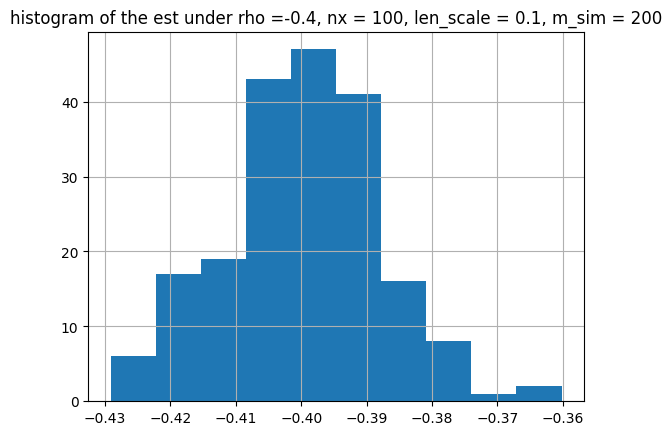

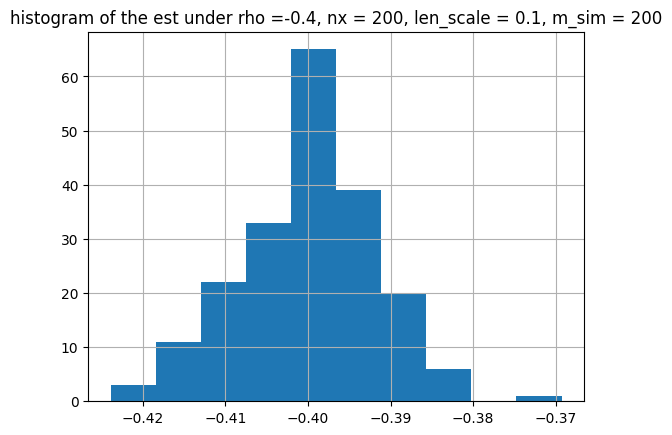

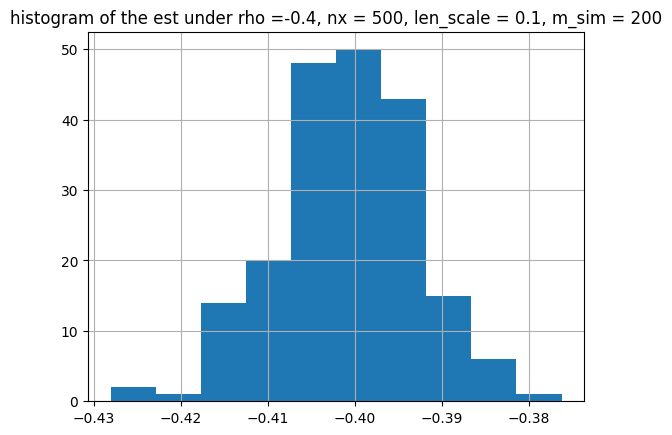

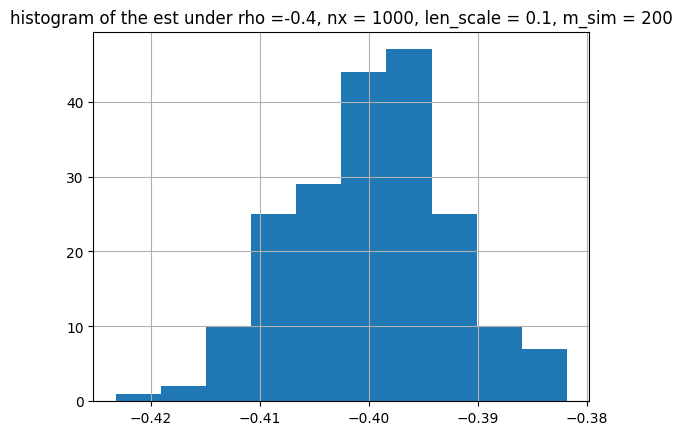

In [34]:
def plot_est(df):
    for i in df['setting_id'].unique():
        df_single = df[df["setting_id"] ==i].reset_index(drop=True)
        df_single['est'].hist()
        plt.title(f"histogram of the est under rho ={df_single['rho'][1]}, nx = {df_single['nx'][1]}, len_scale = {df_single['len_scale'][1]}, m_sim = {df_single['m_sim'][1]}")
        plt.show()
plot_est(df)

In [ ]:
# backup codes
def get_rho_trunc(rho, nx=64, ny=None, var=1.0, len_scale=10.0, seed=None, M_trunc = 10000):    
    # if seed = None, rng.integers will genereate a random number
    rng = np.random.default_rng(seed)
    X_point_ls = []
    Y_point_ls = []
    if ny is None:
        ny = nx
    # the location of the point does not matter due to stationarity, here i use center of the field just for convenience 
    X_center = int(np.ceil(nx/2))
    Y_center = int(np.ceil(ny/2))
    # this step may take a long time with a large loop
    # ?but maybe we do not need to do this because when M_trunc is very large, the rho after truncation should be very similar to the rho before truncation
    # also in reality, the gaussian field generated is already bounded due to computer storage 
    for i in range(50):
        X,Y = gen_field(rho, nx, ny, var, len_scale, seed=rng.integers(0, 1e9), M_trunc = M_trunc)
        X_point_ls.append(X[X_center,Y_center])
        Y_point_ls.append(Y[X_center,Y_center])
    return np.corrcoef(X_point_ls, Y_point_ls)[0, 1]
get_rho_trunc(0.5, nx=64, ny=None, var=1.0, len_scale=10.0, seed=1, M_trunc = 10000)

In [171]:
X = np.array([1,2,3])
n = len(X)
print(n)
isinstance(n, int)

3


True

In [237]:
rng = np.random.default_rng(0)
model = gs.Gaussian(dim=1, var=1, len_scale=5)
msim = 500
n = 50
x = np.arange(n) - n//2
srf = gs.SRF(model)

time_series_all0  = np.zeros((msim, n))
time_series_all1 = np.zeros((msim, n))
for i in range(msim):
    time_series_all1[i,:] = srf.structured(x, seed=rng.integers(0, 1e9))
    time_series_all0[i,:] = np.random.normal(size = n)

print(time_series_all1.shape)

(500, 50)


In [236]:
x = y = np.zeros(10)
x[5] = 10
print(x)
print(y)

np.all(time_series_all1==time_series_all0)

[ 0.  0.  0.  0.  0. 10.  0.  0.  0.  0.]
[ 0.  0.  0.  0.  0. 10.  0.  0.  0.  0.]


True

In [233]:
time_series_all1[:,1]

array([ 0.41233661,  0.36209688, -0.82789221, -0.46065744,  1.13572909,
       -1.28874641, -0.35410792, -0.91397971, -0.47531393, -0.31354852,
       -0.44745056,  1.00637771,  1.86597352,  0.49869426,  0.1638906 ,
        0.71544937,  1.21499222, -0.51518957,  0.89210371, -0.34909273,
        0.71292879, -0.44136512, -0.97550898,  0.5874347 , -0.25578099,
       -0.55812439,  0.4124867 , -0.66169965, -1.12034441, -0.4555581 ,
        1.69316439,  0.29079391, -1.60190887, -0.49378706, -0.37788639,
        0.54326916,  2.71716129, -0.62461704,  0.74155962,  1.52404339,
       -0.89583305,  0.61017388, -1.03772241, -1.87616813, -1.47893055,
       -0.73006033, -2.37328872,  1.65623442,  1.67794848, -0.39822045,
       -0.27886696, -0.71788709, -1.01381096,  1.59842466,  0.13732702,
        0.50934062, -1.22309774,  0.04392133,  1.43650873, -0.00684703,
       -0.36572177, -0.62860255, -0.27708948, -0.34818536, -1.54268096,
       -0.84043868, -1.06137837,  0.53245807, -1.702422  ,  0.08

In [234]:
time_series_all0[:,1]

array([ 0.41233661,  0.36209688, -0.82789221, -0.46065744,  1.13572909,
       -1.28874641, -0.35410792, -0.91397971, -0.47531393, -0.31354852,
       -0.44745056,  1.00637771,  1.86597352,  0.49869426,  0.1638906 ,
        0.71544937,  1.21499222, -0.51518957,  0.89210371, -0.34909273,
        0.71292879, -0.44136512, -0.97550898,  0.5874347 , -0.25578099,
       -0.55812439,  0.4124867 , -0.66169965, -1.12034441, -0.4555581 ,
        1.69316439,  0.29079391, -1.60190887, -0.49378706, -0.37788639,
        0.54326916,  2.71716129, -0.62461704,  0.74155962,  1.52404339,
       -0.89583305,  0.61017388, -1.03772241, -1.87616813, -1.47893055,
       -0.73006033, -2.37328872,  1.65623442,  1.67794848, -0.39822045,
       -0.27886696, -0.71788709, -1.01381096,  1.59842466,  0.13732702,
        0.50934062, -1.22309774,  0.04392133,  1.43650873, -0.00684703,
       -0.36572177, -0.62860255, -0.27708948, -0.34818536, -1.54268096,
       -0.84043868, -1.06137837,  0.53245807, -1.702422  ,  0.08

(array([ 1.,  2.,  1.,  4., 11., 22., 25., 42., 51., 65., 63., 58., 53.,
        42., 23., 15.,  8.,  4.,  7.,  3.]),
 array([-3.27827696, -2.9652716 , -2.65226625, -2.33926089, -2.02625554,
        -1.71325018, -1.40024483, -1.08723948, -0.77423412, -0.46122877,
        -0.14822341,  0.16478194,  0.4777873 ,  0.79079265,  1.10379801,
         1.41680336,  1.72980871,  2.04281407,  2.35581942,  2.66882478,
         2.98183013]),
 <BarContainer object of 20 artists>)

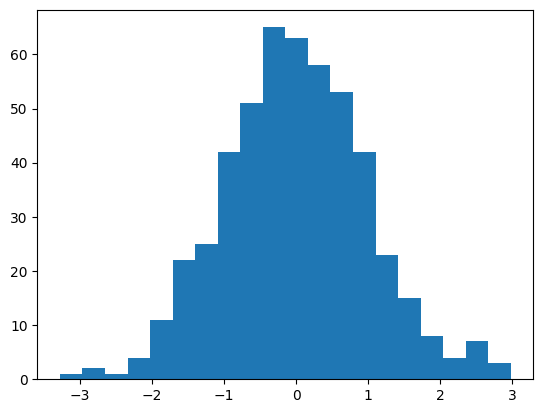

In [238]:
#np.histogram(time_series_all[:,1])
plt.hist(time_series_all1[:,0], bins = 20)

(array([ 2.,  1.,  7., 12., 21., 24., 30., 47., 45., 51., 52., 44., 35.,
        30., 30., 22., 27.,  7.,  2., 11.]),
 array([-2.56852366, -2.32410963, -2.07969559, -1.83528155, -1.59086751,
        -1.34645347, -1.10203944, -0.8576254 , -0.61321136, -0.36879732,
        -0.12438328,  0.12003075,  0.36444479,  0.60885883,  0.85327287,
         1.09768691,  1.34210094,  1.58651498,  1.83092902,  2.07534306,
         2.3197571 ]),
 <BarContainer object of 20 artists>)

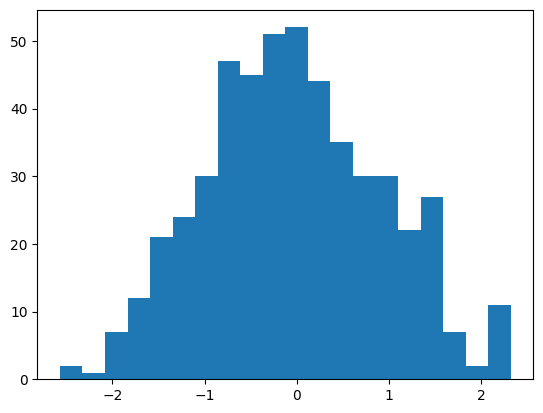

In [239]:
#np.histogram(time_series_all[:,1])
plt.hist(time_series_all0[:,0], bins = 20)